# 00 · Results and figures (runs on CPU, no GPU needed)
**Pranav Kalla, Pranav Prabhakar**

This notebook rebuilds every figure and headline number in the report from the result files in `results/`.
Those files were written by notebooks `01`–`17`, which need a GPU (Colab T4 / Kaggle 2×T4) and a Hugging Face token.
Run from the repository root: `jupyter nbconvert --execute --to notebook notebooks/00_results_and_figures.ipynb`.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')
import os, glob, subprocess, sys, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
for s in ['make_schematic.py', 'make_figs.py', 'make_figs2.py', 'make_fig_ds2.py']:
    r = subprocess.run([sys.executable, os.path.join('figures_code', s)], capture_output=True, text=True)
    print(s, 'OK' if r.returncode == 0 else r.stderr[-800:])
sorted(os.path.basename(f) for f in glob.glob('figures/*.png'))

make_schematic.py OK


make_figs.py OK


make_figs2.py OK


make_fig_ds2.py OK


['fig_colliders.png',
 'fig_dosource.png',
 'fig_ds2.png',
 'fig_main.png',
 'fig_models.png',
 'fig_schematic.png',
 'fig_steering.png',
 'fig_tf.png']

## 1 · The question (Fig. 1)
Reading a fact (**see**) should raise belief in its cause and its effect; an imposed fact (**do**) only its effect. Which pattern does a **patched** hidden state follow?

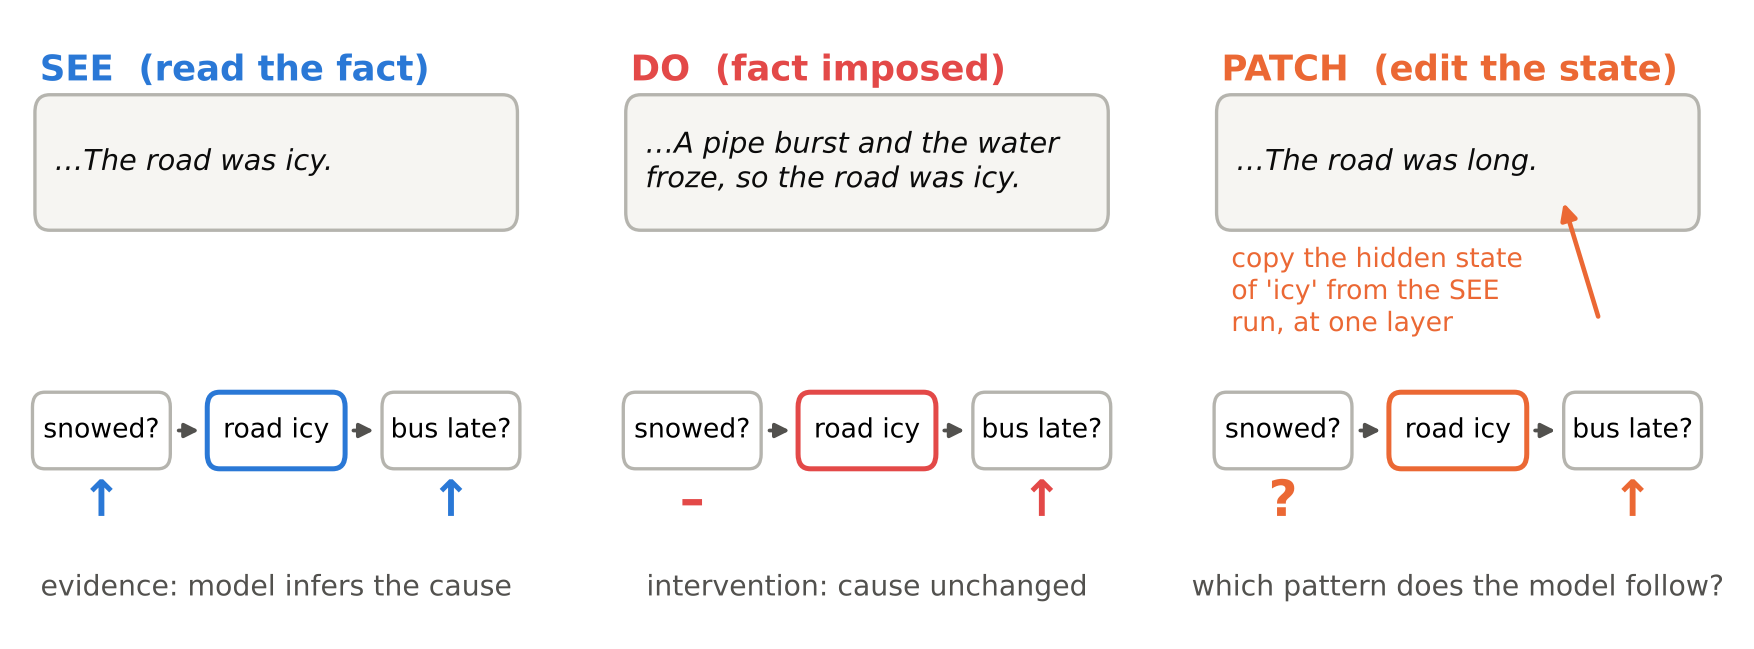

In [2]:
display(Image('figures/fig_schematic.png', width=820))

## 2 · Does the model separate seeing from doing in text? (validity filters)

In [3]:
rows = []
for name, f in [('Qwen chains, exploration', 'results/main_qwen/P_exploration_reference_scenarios.csv'),
                ('Qwen chains, confirmation', 'results/main_qwen/P_confirmation_reference_scenarios.csv'),
                ('Qwen chains, fresh variants (DS2)', 'results/ds2_qwen/DS2_qwen_reference_scenarios.csv'),
                ('Llama chains, fresh variants (DS2)', 'results/ds2_llama/DS2_llama_reference_scenarios.csv')]:
    d = pd.read_csv(f); col = [c for c in d.columns if 'valid' in c.lower()]
    rows.append(dict(set=name, scenarios=len(d), valid=int(d[col[0]].sum()) if col else None))
pd.DataFrame(rows)

,set,scenarios,valid
0,"Qwen chains, exploration",20,15
1,"Qwen chains, confirmation",25,15
2,"Qwen chains, fresh variants (DS2)",30,30
3,"Llama chains, fresh variants (DS2)",23,22


## 3 · Steering looked like 'seeing', but it was a yes-bias (Fig. 2)

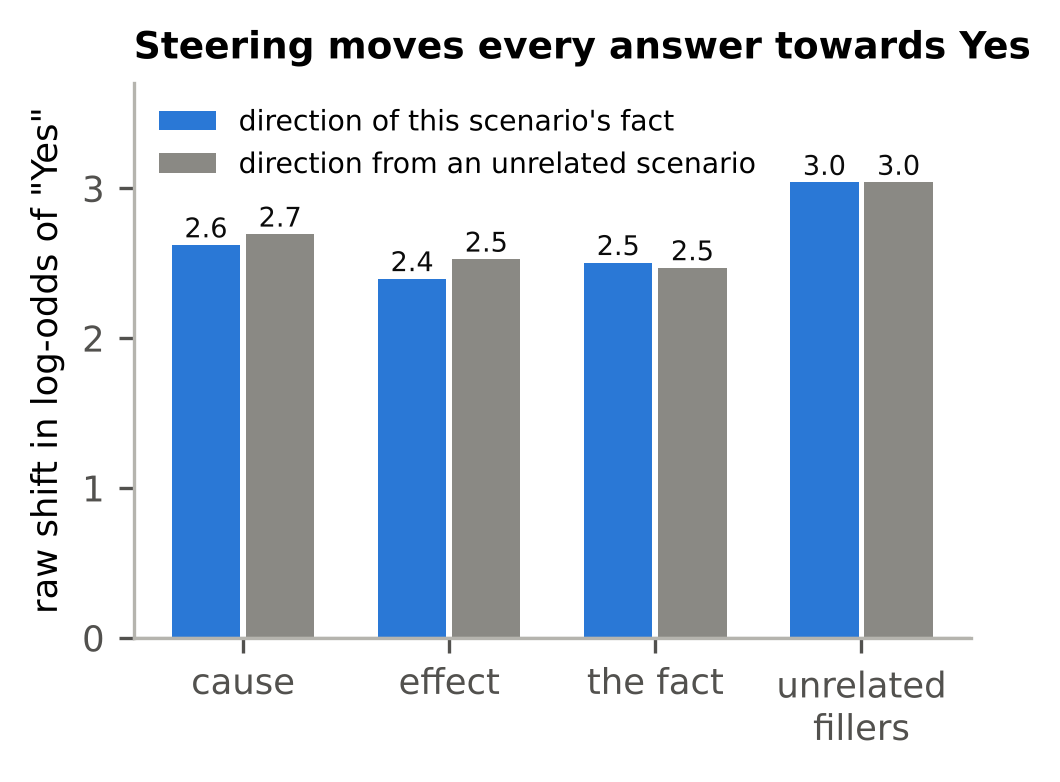

In [4]:
display(Image('figures/fig_steering.png', width=650))

## 4 · Main result: patched facts act as evidence, D ≈ 0 (Fig. 3)

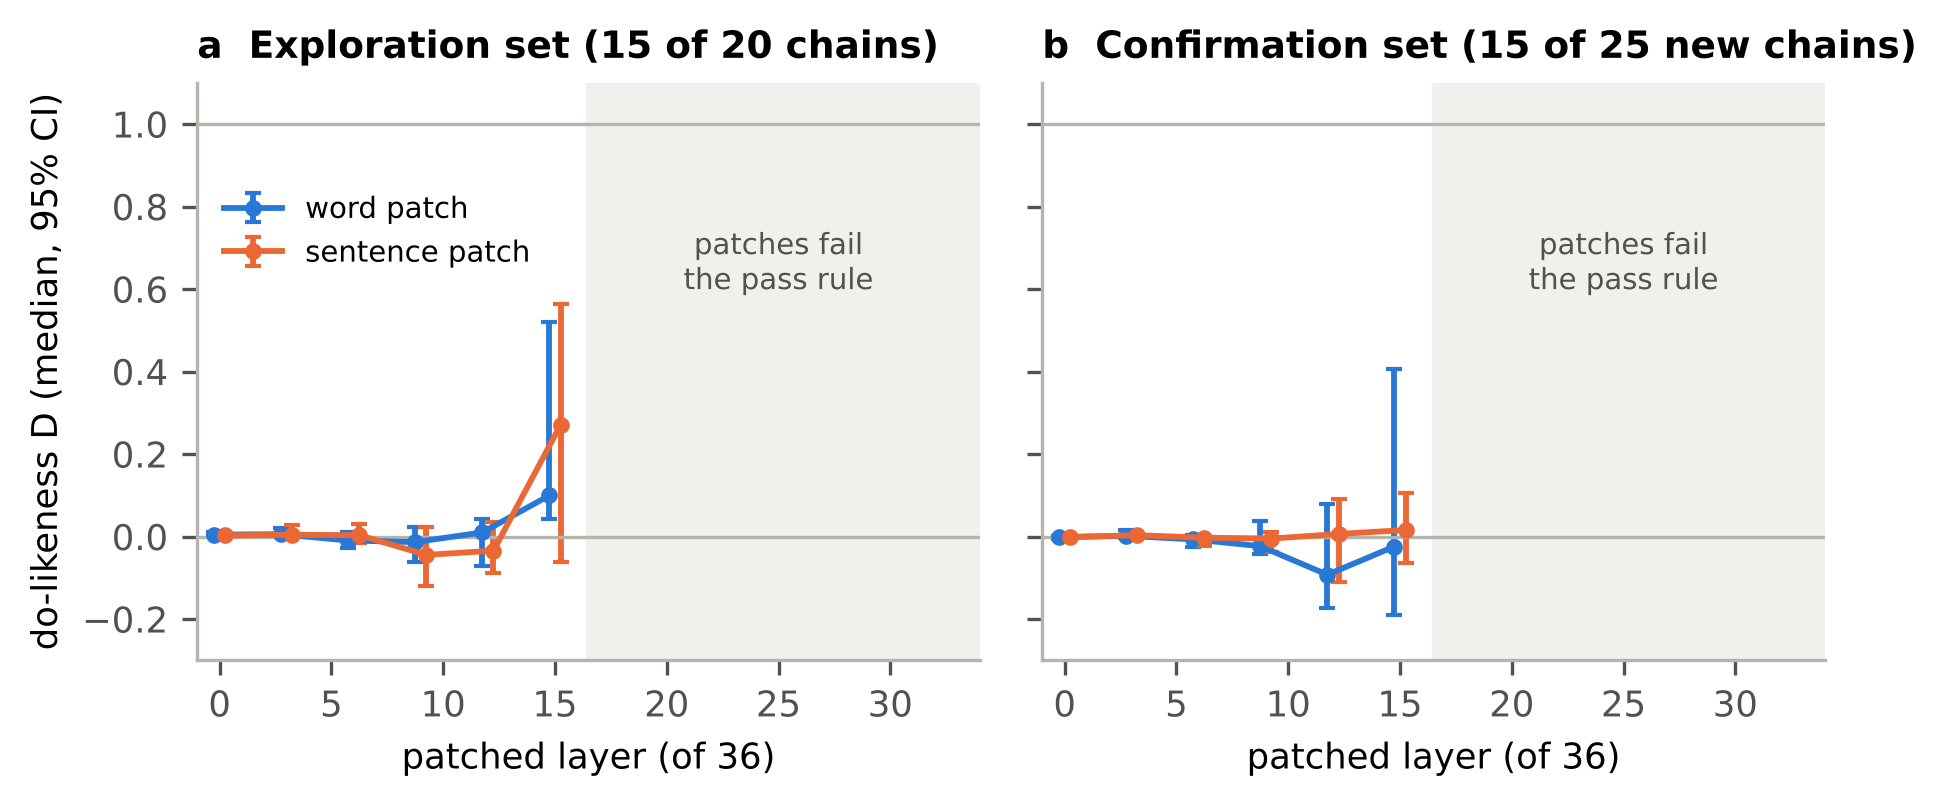

,layer,mode,works_rate,n_scored,D_median,D_clip_median,ci_lo,ci_hi,passes
0,0,sentence,0.933333,14,-0.001004,0.000000,-0.002781,0.001528,True
1,0,word,0.933333,14,-0.001544,0.000000,-0.006082,0.000930,True
2,3,sentence,1.000000,15,0.003384,0.003384,-0.001605,0.004790,True
3,3,word,1.000000,15,0.001882,0.001882,-0.004589,0.016866,True
4,6,sentence,1.000000,15,-0.002714,0.000000,-0.022285,0.000122,True
5,6,word,1.000000,15,-0.006696,0.000000,-0.025153,0.004092,True
6,9,sentence,1.000000,15,-0.004770,0.000000,-0.037388,0.010585,True
7,9,word,1.000000,15,-0.023289,0.000000,-0.041085,0.036794,True
8,12,sentence,1.000000,15,0.006290,0.006290,-0.109524,0.090661,True
9,12,word,1.000000,15,-0.092399,0.000000,-0.173238,0.078101,True


In [5]:
display(Image('figures/fig_main.png', width=820))
s = pd.read_csv('results/main_qwen/P_confirmation_D_summary.csv'); s.head(20)

## 5 · Colliders: a patched C explains away like a read C (Fig. 4)

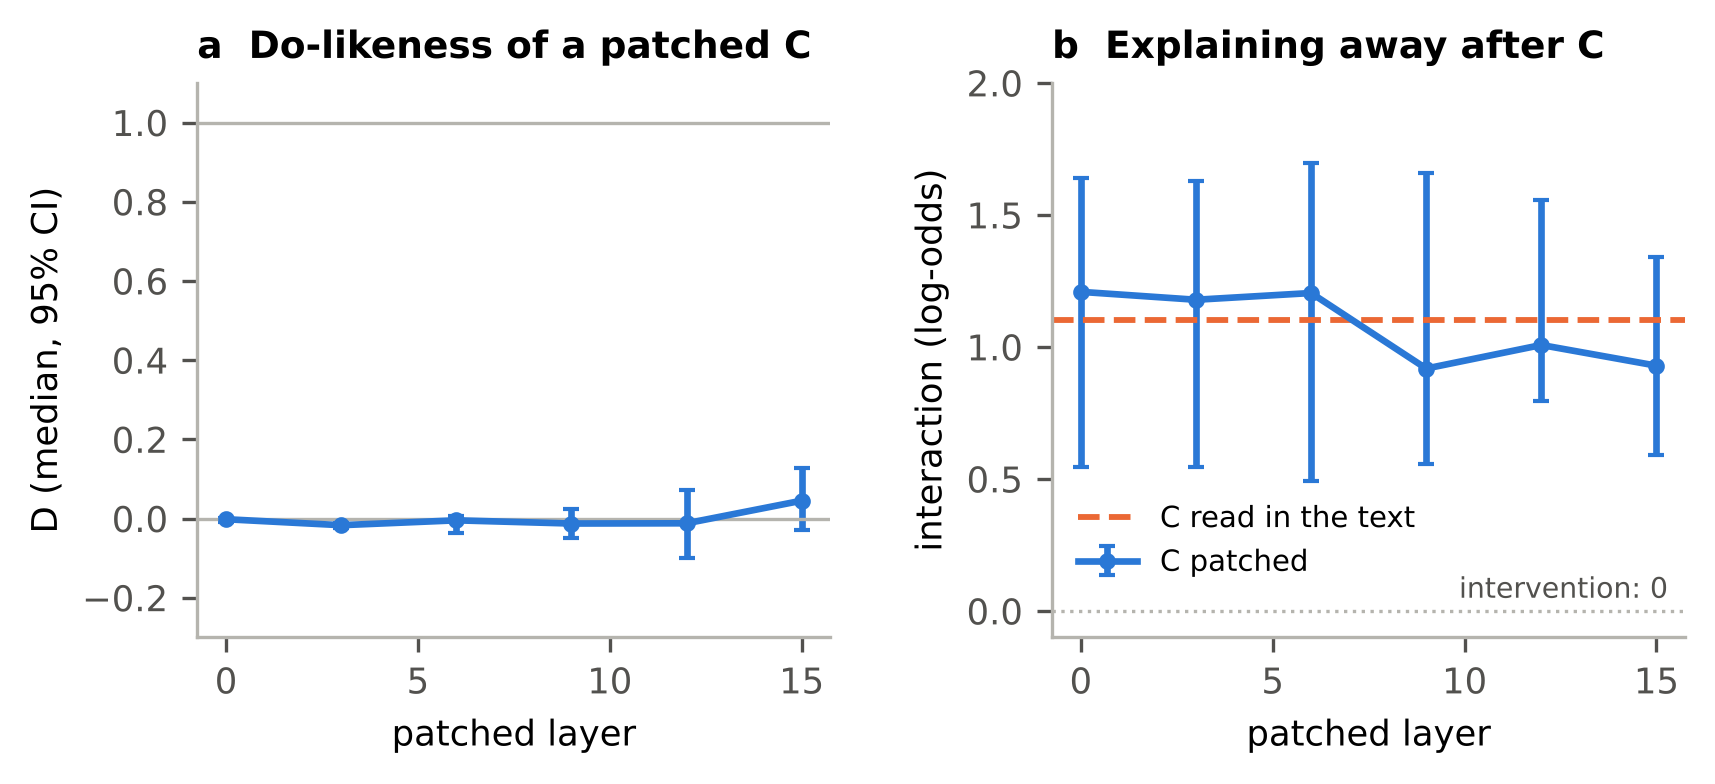

,layer,works_rate,n_scored,D_median,D_lo,D_hi,EA_patch_median,EA_lo,EA_hi,EA_text_median,passes
0,0,1.000000,12,-0.001753,-0.007661,0.001408,1.208631,0.545177,1.638192,1.102370,True
1,3,1.000000,12,-0.016811,-0.024249,-0.005336,1.178730,0.545907,1.629320,1.102370,True
2,6,1.000000,12,-0.004538,-0.036128,0.006878,1.204173,0.490919,1.696761,1.102370,True
3,9,1.000000,12,-0.012621,-0.048089,0.022877,0.918153,0.555771,1.659289,1.102370,True
4,12,1.000000,12,-0.012046,-0.100638,0.072779,1.007306,0.795305,1.557428,1.102370,True
5,15,1.000000,12,0.045056,-0.028305,0.126582,0.928983,0.589662,1.339387,1.102370,True
6,18,0.166667,2,0.021588,NaN,NaN,0.460658,NaN,NaN,0.690737,False
7,21,0.000000,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
8,24,0.000000,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
9,27,0.000000,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


In [6]:
display(Image('figures/fig_colliders.png', width=820))
pd.read_csv('results/main_qwen/H3_summary.csv').head(20)

## 6 · Three model families (Fig. 5) and answer format (Fig. 6)

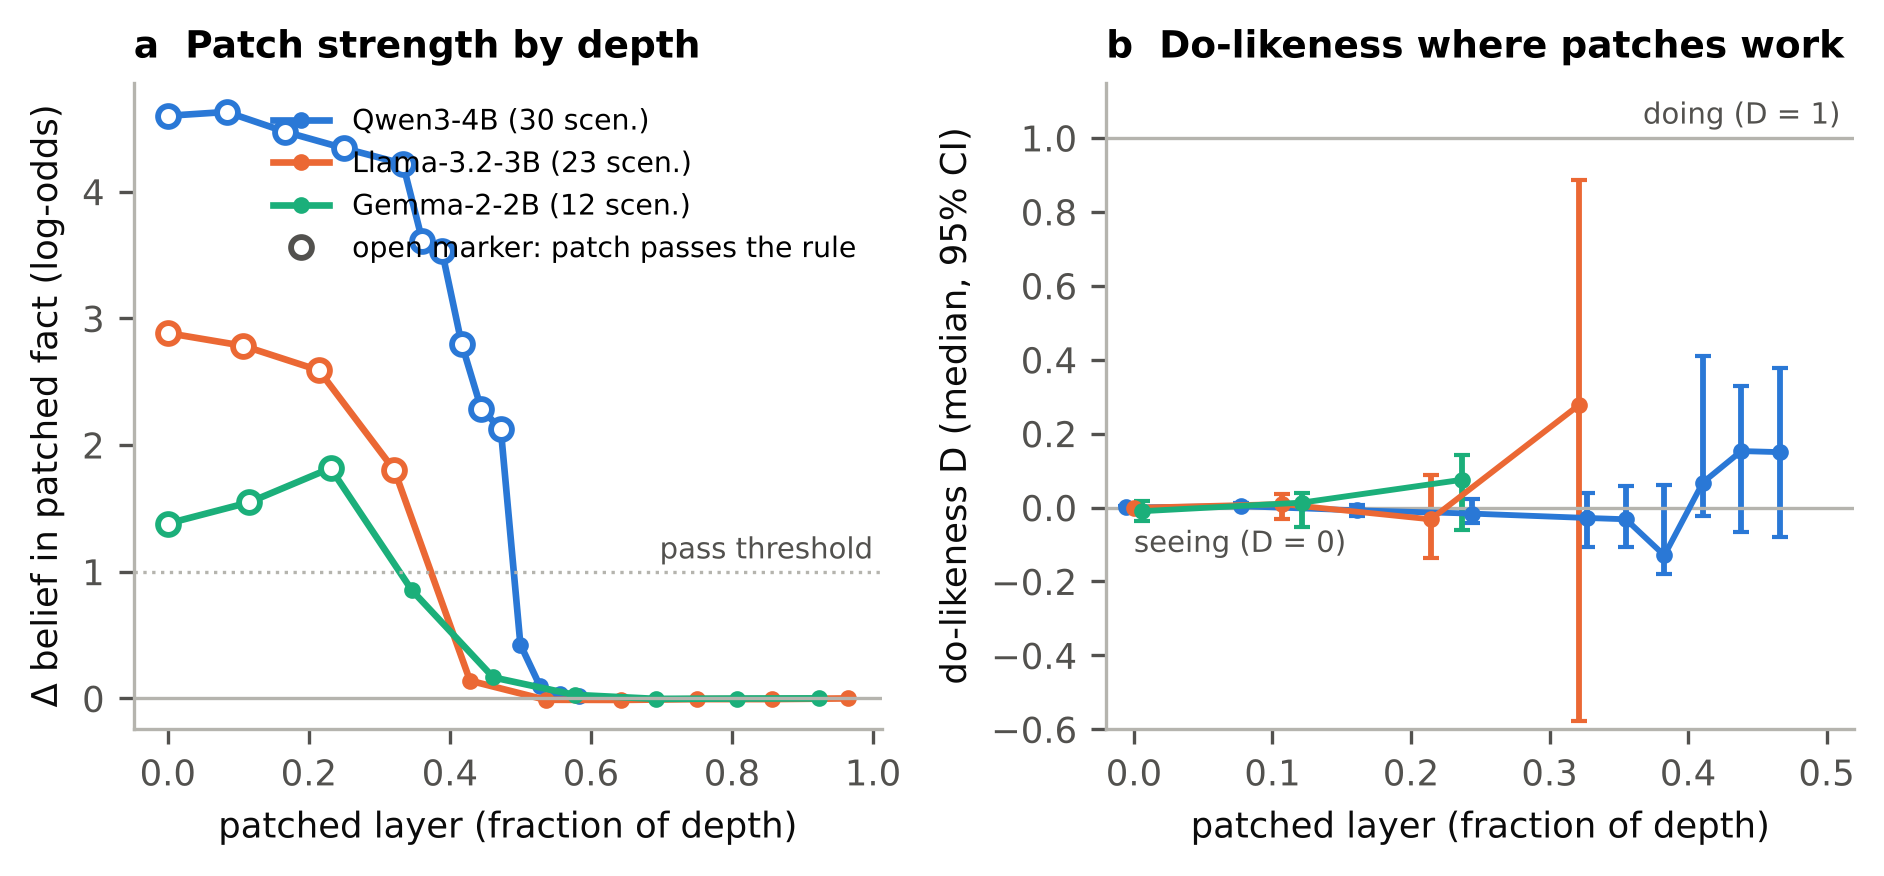

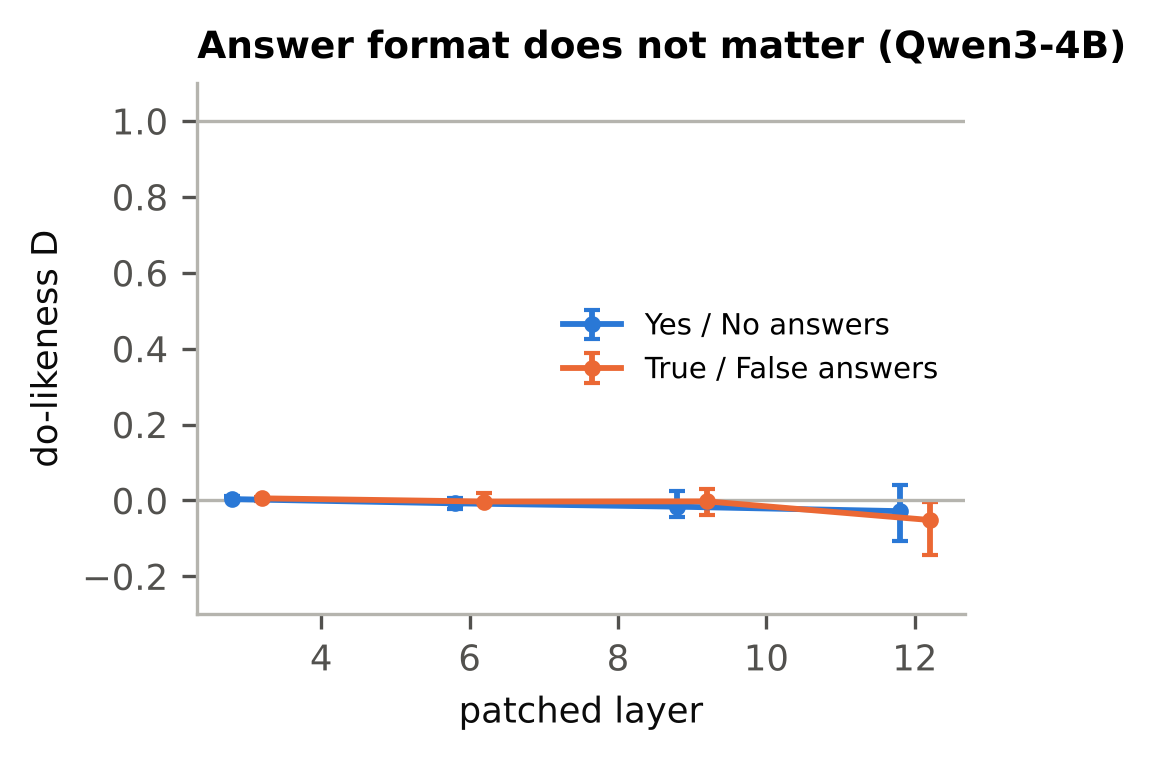

In [7]:
display(Image('figures/fig_models.png', width=820)); display(Image('figures/fig_tf.png', width=420))

## 7 · H2: the cause is not copied in with the patch

In [8]:
pd.read_csv('results/main_qwen/H2_summary.csv').head(20)

,layer,n,D_true,D_minus_cause,D_minus_unrel,shift_cause,shift_cause_lo,shift_cause_hi,shift_unrel,shift_unrel_lo,shift_unrel_hi,dmedC_true,dmedC_minus_cause,dcauseC_true,dcauseC_minus_cause,deffectC_true,deffectC_minus_cause
0,0,28,0.001051,0.000655,0.001260,-0.000987,-0.003002,0.000751,0.000501,-0.001334,0.000980,4.599237,4.597695,2.138304,2.138143,1.773531,1.772675
1,3,30,0.003608,0.002842,0.004132,-0.001156,-0.001641,0.000960,0.000148,-0.000452,0.000966,4.629647,4.628164,2.294015,2.295129,1.863804,1.862977
2,6,30,-0.006854,-0.005148,-0.007265,0.000609,-0.001561,0.003100,-0.000400,-0.002344,0.000406,4.472828,4.472015,2.300950,2.298309,1.863002,1.862719
3,9,30,-0.016257,-0.023084,-0.019956,0.000811,-0.004162,0.001769,0.000339,-0.001507,0.002517,4.342871,4.339551,2.303977,2.300714,1.844500,1.844818
4,12,28,-0.027151,-0.039290,-0.026186,-0.000268,-0.006771,0.012407,0.000439,-0.011121,0.006285,4.220524,4.199047,2.255410,2.211240,1.722415,1.689868
5,15,19,0.071905,0.050249,0.062954,-0.009847,-0.024846,0.004308,-0.011294,-0.032047,0.006881,2.800157,2.723363,1.472506,1.373517,1.188568,1.076501


## 8 · Second finding: where does 'this fact was imposed' live? (Figs. 7–8)

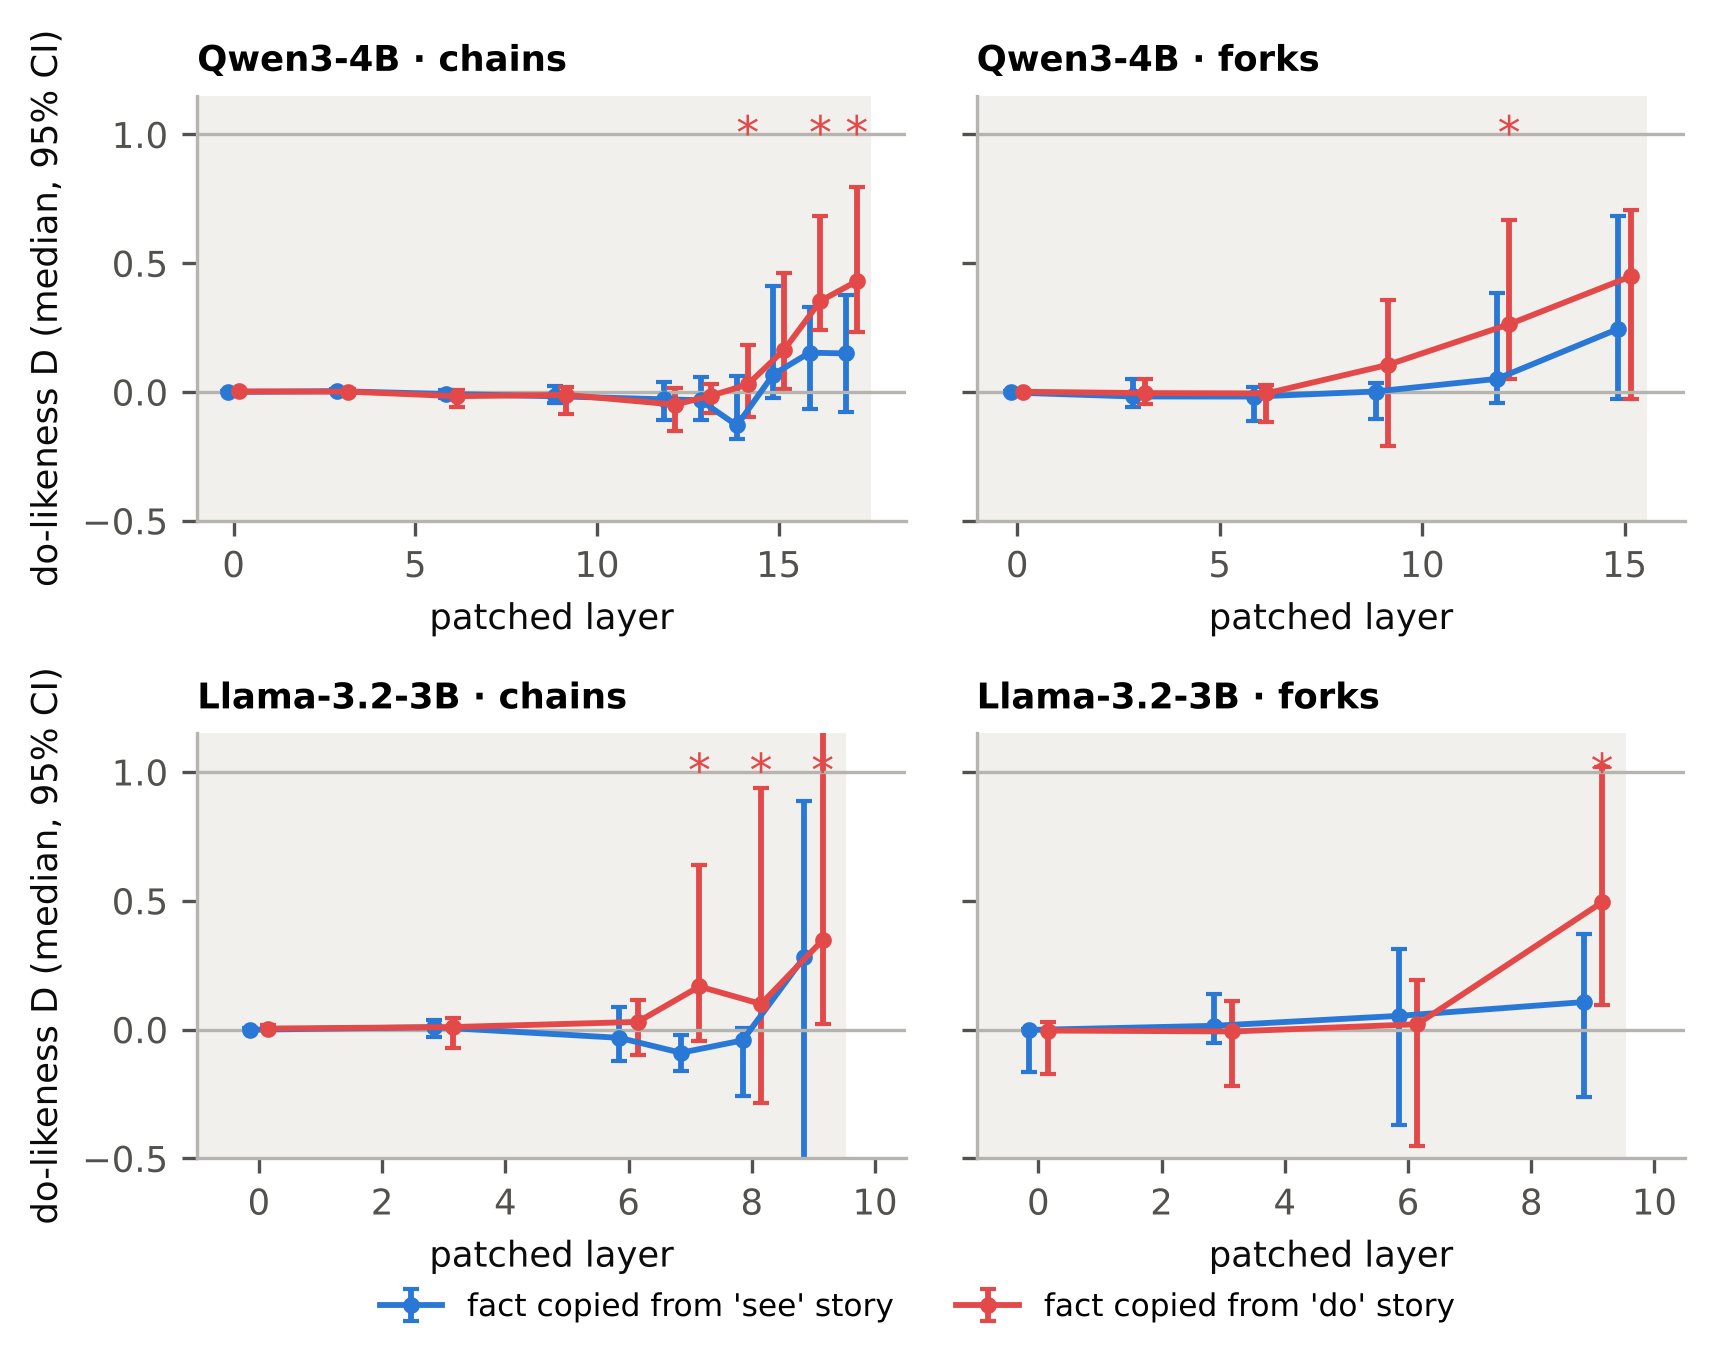

,panel,layer,diff,lo,hi,n
0,Qwen3-4B · chains,0,0.003,0.001,0.004,28
1,Qwen3-4B · chains,3,-0.005,-0.008,0.002,30
2,Qwen3-4B · chains,6,-0.008,-0.036,0.003,30
3,Qwen3-4B · chains,9,-0.017,-0.058,0.022,30
4,Qwen3-4B · chains,12,0.014,-0.120,0.045,28
5,Qwen3-4B · chains,13,-0.001,-0.078,0.116,27
6,Qwen3-4B · chains,14,0.126,0.027,0.174,24
7,Qwen3-4B · chains,15,0.101,-0.022,0.235,17
8,Qwen3-4B · chains,16,0.169,0.003,0.377,8
9,Qwen3-4B · chains,17,0.242,0.096,0.553,4


In [9]:
display(Image('figures/fig_dosource.png', width=720))
pd.read_csv('figures/data_dosource_paired_diff.csv').round(3).head(40)

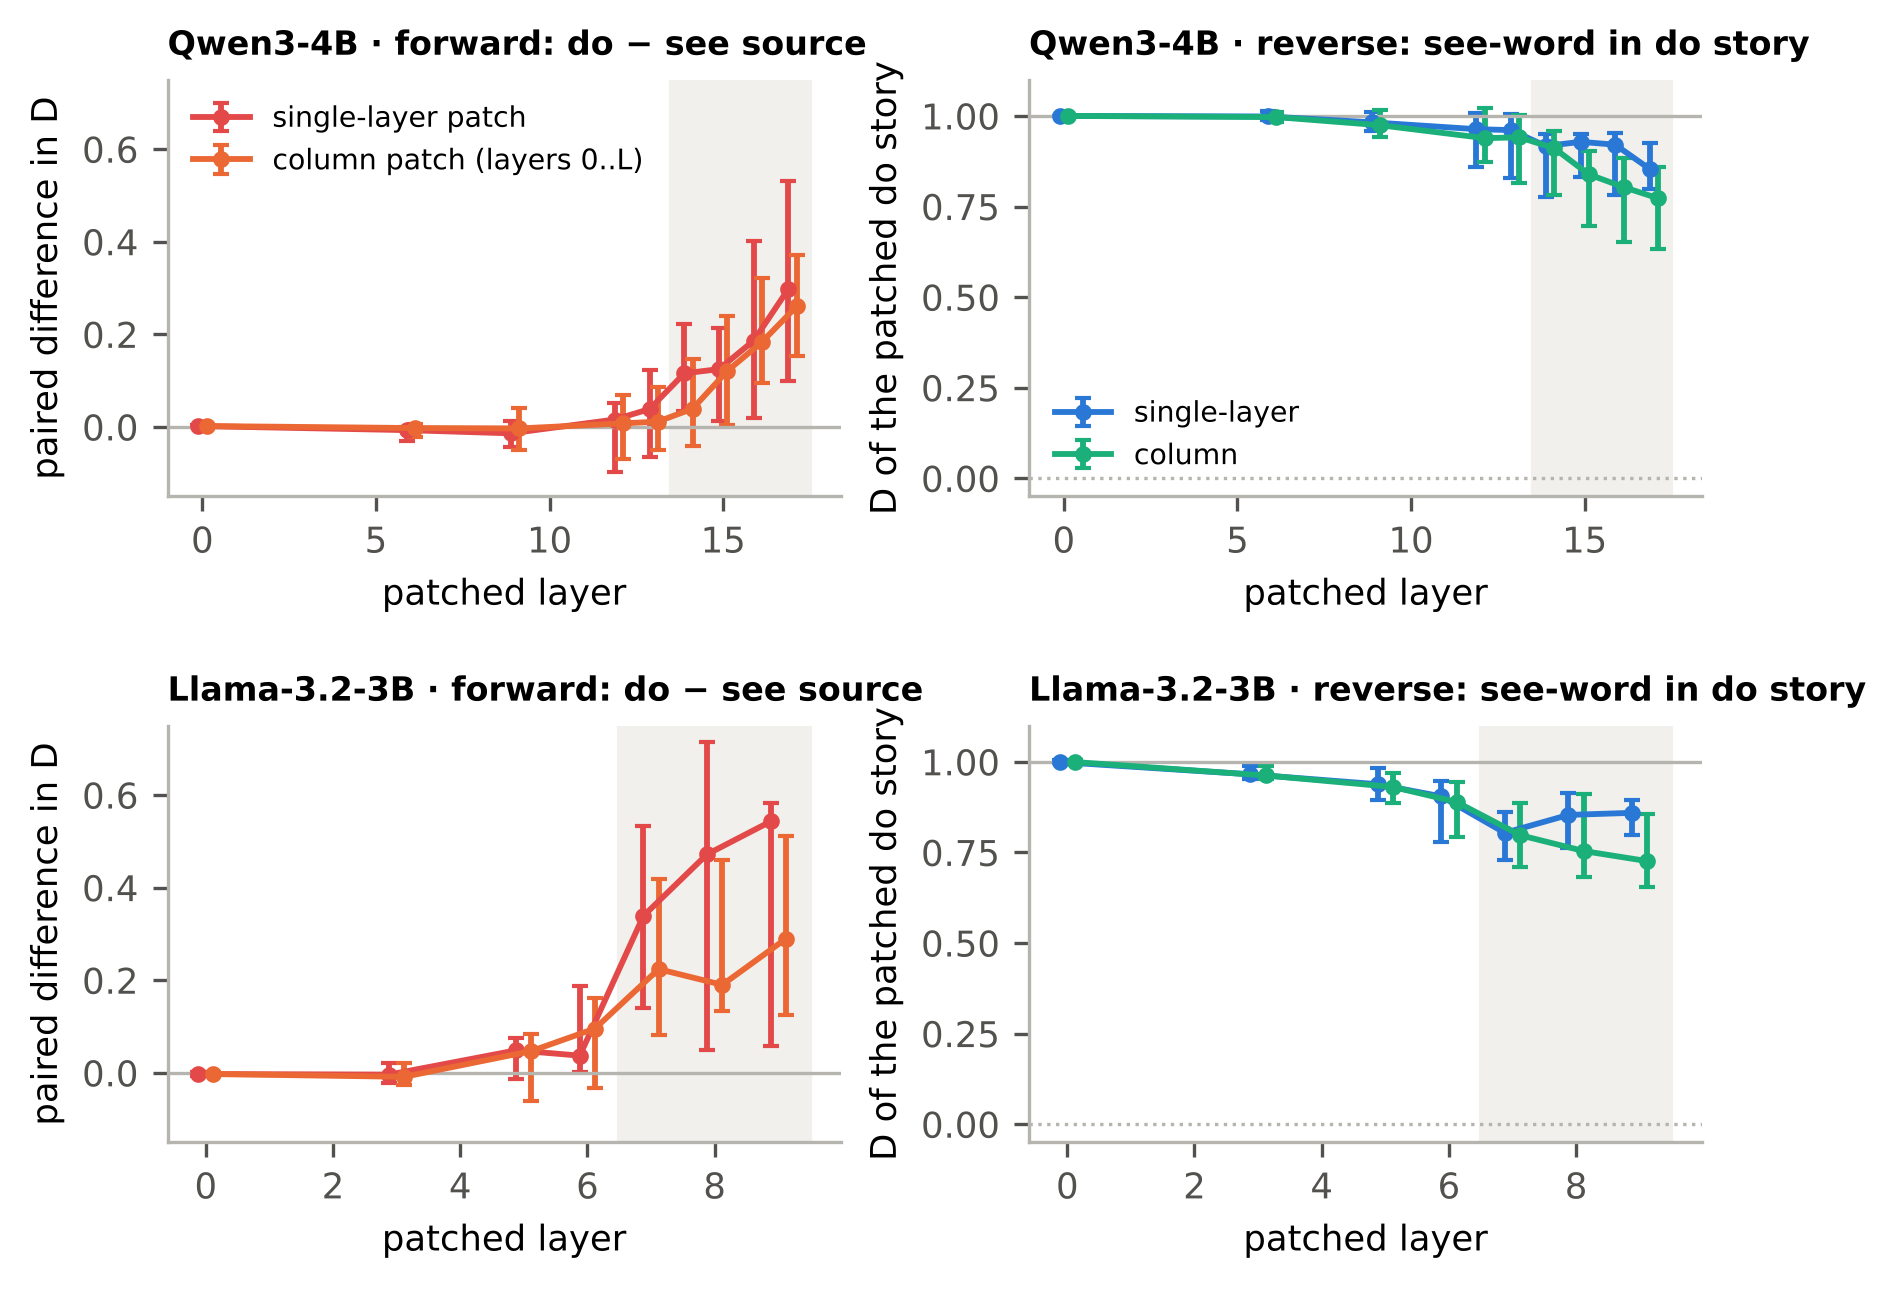

results/ds2_qwen/DS2_qwen_summary.csv


,test,layer,mode,D_see_src,see_lo,see_hi,D_do_src,do_lo,do_hi,diff,diff_lo,diff_hi,p_signflip,n_paired,D_rev,rev_lo,rev_hi,n,works
0,forward,0,column,-0.001,-0.002,0.002,0.002,-0.001,0.008,0.002,0.000,0.005,0.001,28.0,NaN,NaN,NaN,NaN,NaN
1,forward,0,single,-0.001,-0.002,0.002,0.002,-0.001,0.008,0.002,0.000,0.005,0.001,28.0,NaN,NaN,NaN,NaN,NaN
2,forward,6,column,0.000,-0.001,0.002,-0.004,-0.035,0.009,-0.002,-0.021,0.008,0.201,30.0,NaN,NaN,NaN,NaN,NaN
3,forward,6,single,-0.008,-0.021,0.006,-0.007,-0.061,0.009,-0.007,-0.030,0.000,0.040,30.0,NaN,NaN,NaN,NaN,NaN
4,forward,9,column,0.000,-0.001,0.002,0.002,-0.045,0.049,-0.003,-0.049,0.040,0.293,29.0,NaN,NaN,NaN,NaN,NaN
5,forward,9,single,-0.002,-0.044,0.028,-0.010,-0.056,0.017,-0.014,-0.044,0.013,0.537,30.0,NaN,NaN,NaN,NaN,NaN
6,forward,12,column,0.000,-0.001,0.002,0.015,-0.062,0.071,0.008,-0.068,0.070,0.719,30.0,NaN,NaN,NaN,NaN,NaN
7,forward,12,single,-0.002,-0.104,0.054,-0.028,-0.149,0.037,0.016,-0.097,0.052,0.538,28.0,NaN,NaN,NaN,NaN,NaN
8,forward,13,column,0.000,-0.001,0.002,0.011,-0.049,0.085,0.012,-0.051,0.086,0.449,28.0,NaN,NaN,NaN,NaN,NaN
9,forward,13,single,-0.033,-0.113,0.082,-0.022,-0.107,0.082,0.039,-0.065,0.124,0.733,28.0,NaN,NaN,NaN,NaN,NaN


results/ds2_llama/DS2_llama_summary.csv


,test,layer,mode,D_see_src,see_lo,see_hi,D_do_src,do_lo,do_hi,diff,diff_lo,diff_hi,p_signflip,n_paired,D_rev,rev_lo,rev_hi,n,works
0,forward,0,column,-0.001,-0.005,0.000,-0.001,-0.009,0.014,-0.002,-0.005,0.003,0.839,23.0,NaN,NaN,NaN,NaN,NaN
1,forward,0,single,-0.001,-0.005,0.000,-0.001,-0.009,0.014,-0.002,-0.006,0.003,0.839,23.0,NaN,NaN,NaN,NaN,NaN
2,forward,3,column,-0.001,-0.005,0.000,-0.003,-0.021,0.021,-0.008,-0.025,0.021,0.108,23.0,NaN,NaN,NaN,NaN,NaN
3,forward,3,single,0.001,-0.020,0.015,-0.001,-0.058,0.037,-0.004,-0.021,0.022,0.095,23.0,NaN,NaN,NaN,NaN,NaN
4,forward,5,column,-0.001,-0.005,-0.000,0.043,-0.037,0.070,0.047,-0.060,0.085,0.742,23.0,NaN,NaN,NaN,NaN,NaN
5,forward,5,single,0.004,-0.053,0.084,0.019,-0.086,0.152,0.049,-0.014,0.076,0.852,23.0,NaN,NaN,NaN,NaN,NaN
6,forward,6,column,-0.002,-0.005,-0.000,0.054,-0.022,0.154,0.096,-0.033,0.163,0.093,21.0,NaN,NaN,NaN,NaN,NaN
7,forward,6,single,-0.031,-0.143,0.080,-0.000,-0.105,0.109,0.037,0.002,0.187,0.954,23.0,NaN,NaN,NaN,NaN,NaN
8,forward,7,column,-0.002,-0.006,-0.000,0.227,0.089,0.411,0.224,0.081,0.418,0.001,21.0,NaN,NaN,NaN,NaN,NaN
9,forward,7,single,-0.093,-0.191,0.026,0.085,-0.103,0.708,0.339,0.139,0.533,0.000,17.0,NaN,NaN,NaN,NaN,NaN


In [10]:
display(Image('figures/fig_ds2.png', width=820))
for f in ['results/ds2_qwen/DS2_qwen_summary.csv', 'results/ds2_llama/DS2_llama_summary.csv']:
    print(f); display(pd.read_csv(f).round(3).head(40))

## 9 · Pre-registered predictions and outcomes
| Test | Predictions | Held |
|---|---|---|
| Confirmation chains (Qwen) | 4 | 4 |
| Colliders (Qwen) | 4 | 4 |
| Forks (Qwen, Llama) | per model | all |
| True/False format (Qwen) | 3 | 3 |
| DS2 late "intervention" signal (Qwen + Llama) | 5 | 4 in full, 1 in direction only |

Prediction files (timestamped before each run) are in `pre_registrations/`.